# SVR on energy: chronological tuning and evaluation

The lesson's prose and sample code disagree on dates. This extended
experiment uses **September–October 2014 for training, November for
validation, and December for the final test**. It preserves the lesson's
lag-window SVR approach while providing a genuine tuning period.
`lookback=4` corresponds to the lesson's five-element window: four
features followed by one target. Later lookbacks are twelve and twenty-four.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVR

def lagged(series, lookback):
    frame = pd.DataFrame({'target':series})
    for lag in range(1,lookback+1):
        frame[f'lag_{lag}'] = series.shift(lag)
    return frame.dropna()

check = lagged(pd.Series(range(10)),4)
assert check.loc[4,'target']==4 and check.loc[4,'lag_1']==3 and check.loc[4,'lag_4']==0

configs = [
    {'kernel':'linear','C':10,'gamma':'scale','epsilon':0.02},
    {'kernel':'rbf','C':1,'gamma':0.1,'epsilon':0.05},
    {'kernel':'rbf','C':10,'gamma':0.5,'epsilon':0.05},
    {'kernel':'rbf','C':10,'gamma':'scale','epsilon':0.02},
    {'kernel':'rbf','C':100,'gamma':'scale','epsilon':0.01},
]

In [2]:
energy = pd.read_csv('../../../7-TimeSeries/data/energy.csv',parse_dates=['timestamp']).set_index('timestamp').asfreq('h')
series = energy.load
assert series.notna().all() and series.gt(0).all()

In [3]:
rows = []
for lookback in [4, 12, 24]:
    frame = lagged(series,lookback)
    train = frame.loc['2014-09-01':'2014-11-01'].loc[lambda value:value.index < pd.Timestamp('2014-11-01')]
    validation = frame.loc['2014-11-01':'2014-12-01'].loc[lambda value:value.index < pd.Timestamp('2014-12-01')]
    for config in configs:
        model = TransformedTargetRegressor(
            regressor=make_pipeline(MinMaxScaler(),SVR(**config)),transformer=MinMaxScaler())
        model.fit(train.drop(columns='target'),train.target)
        predicted = model.predict(validation.drop(columns='target'))
        rows.append({'lookback':lookback,**config,
                     'validation_MAPE_percent':100*mean_absolute_percentage_error(validation.target,predicted)})
winner = min(rows,key=lambda row:row['validation_MAPE_percent'])
display(pd.DataFrame(rows).sort_values('validation_MAPE_percent').round(5))
print('Selected using validation only:',winner)
frame = lagged(series,int(winner['lookback']))
train = frame.loc['2014-09-01':].loc[lambda value:value.index < pd.Timestamp('2014-12-01')]
test = frame.loc['2014-12-01':].copy()
assert train.index.max() < test.index.min()
parameters = {key:winner[key] for key in ['kernel','C','gamma','epsilon']}
model = TransformedTargetRegressor(
    regressor=make_pipeline(MinMaxScaler(),SVR(**parameters)),transformer=MinMaxScaler())
model.fit(train.drop(columns='target'),train.target)
test['prediction'] = model.predict(test.drop(columns='target'))
test['persistence'] = series.shift(1).reindex(test.index)

,lookback,kernel,C,gamma,epsilon,validation_MAPE_percent
10,24,linear,10,scale,0.02,1.20207
3,4,rbf,10,scale,0.02,1.22617
4,4,rbf,100,scale,0.01,1.25974
8,12,rbf,10,scale,0.02,1.47439
9,12,rbf,100,scale,0.01,1.55295
0,4,linear,10,scale,0.02,1.63274
5,12,linear,10,scale,0.02,1.75368
2,4,rbf,10,0.5,0.05,1.78897
6,12,rbf,1,0.1,0.05,1.92034
1,4,rbf,1,0.1,0.05,2.09023


Selected using validation only: {'lookback': 24, 'kernel': 'linear', 'C': 10, 'gamma': 'scale', 'epsilon': 0.02, 'validation_MAPE_percent': 1.202065099555798}


In [4]:
test['daily_naive'] = series.shift(24).reindex(test.index)
metrics = pd.DataFrame([
    {'method':name,'MAPE_percent':100*mean_absolute_percentage_error(test.target,test[name]),
     'MAE':mean_absolute_error(test.target,test[name]),'RMSE':root_mean_squared_error(test.target,test[name])}
    for name in ['prediction','persistence','daily_naive']
])
print('Refit/test target rows:',len(train),len(test))
assert len(test)==744
display(metrics.round(4))
pd.DataFrame(rows).to_csv('energy-validation.csv',index=False)
metrics.to_csv('energy-metrics.csv',index=False)
train.to_csv('model-training.csv',index_label='timestamp')
test.to_csv('model-test.csv',index_label='timestamp')
joblib.dump(model,'energy-svr.joblib')
loaded = joblib.load('energy-svr.joblib')
np.testing.assert_allclose(loaded.predict(test[train.drop(columns='target').columns]),test.prediction)

Refit/test target rows: 2184 744


,method,MAPE_percent,MAE,RMSE
0,prediction,1.0730,36.6868,52.9028
1,persistence,3.9030,131.2796,172.4979
2,daily_naive,4.7919,162.2056,216.1451


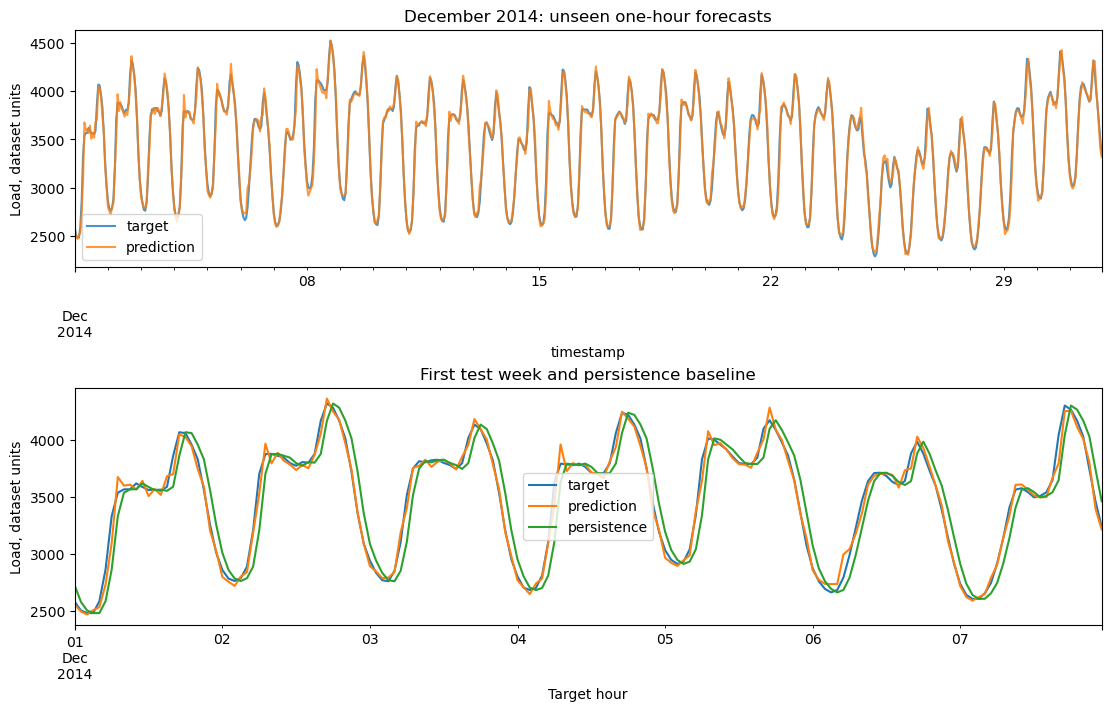

In [5]:
fig, axes = plt.subplots(2,1,figsize=(11,7),layout='constrained')
test[['target','prediction']].plot(ax=axes[0],alpha=0.8)
axes[0].set(title='December 2014: unseen one-hour forecasts',ylabel='Load, dataset units')
test.loc['2014-12-01':'2014-12-07',['target','prediction','persistence']].plot(ax=axes[1])
axes[1].set(title='First test week and persistence baseline',ylabel='Load, dataset units',xlabel='Target hour')
fig.savefig('svr-energy.png',dpi=150)
plt.show()

## Challenge and evaluation limits

The fifteen validation experiments vary kernel, C, gamma, epsilon, and the
number of past hours. Only the validation score chooses a configuration.
Input and target scalers fit on training observations inside the estimator;
final refitting includes November before December is evaluated. The first
test prediction can use the previous month's observed history.

These are rolling **one-hour-ahead** predictions using newly observed lag
values, not a single month-ahead forecast. Evaluating fitted or earlier
whole-series points would not measure generalization. The prediction CSV
supplies the fixed model and held-out outcomes for the later real-world
proposal and debugging exercise, avoiding another unnecessary model.
The [assignment](assignment.ipynb) repeats the exercise on fresh CO2 data.